# 08 同桥长、同桥宽：误差盒是否比“桥长门槛”更会区分该放与该拒

07 的最坏世界组里只有桥长在变，所以事后设一个“桥长 ≤ 33 m 才进”的门槛也能做到 0 碰撞。
这里固定桥的几何（8 m 宽，桥长 18 / 24 / 30 m 各一组），只改变其余条件，看误差盒的入口判断能否区分同一座桥上该放行和该拒绝的世界。

两组世界（`bridge_sim/ext.py: sample_same_geometry`）：

| 组 | 船已知、每个世界不同的量 | 船不知道的量 |
|---|---|---|
| A：已知海流与入口状态 | 海图背景流（东向 0–0.20 m/s）、海图射流幅值 0–0.50 m/s、入口横偏 ±1 m、入口艏向 ±0.15 rad；声明射流误差界固定 0.22 | 射流误差 U[−0.22, 0.22] 及其余界内误差 |
| B：另加各桥位的海图质量 | 同 A，另外每个世界有自己的声明射流误差界 B ~ U[0.05, 0.35]（代表不同桥位的海流图质量，方法知道） | 射流误差 ±B·U[0.6, 1.0]（在该世界自己的界内） |

比较的决策规则（同一世界、同一进近）：

- **桥长门槛**：只看桥长，门槛内总是以固定 1.5 m/s ILOS 进入（07 中最好的固定航速）。在一个固定桥长上，它要么全放、要么全拒。
- **本文方法**：误差盒入口认证 + 选速 + 在线滤波。
- **EKF 3σ**：同一滤波器，误差管换成 3σ。

“能过”= 14 个 ILOS 候选航速中至少一个通过（事后参照）；“不可通过”= 14 个都没通过。

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from bridge_sim.ext import sample_same_geometry, run_batch

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
LENGTHS = (18.0, 24.0, 30.0)
METHODS = ('filter', 'ekf3s', 'oracle')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def worlds(group, n, seed0):
    rng = np.random.default_rng(2030 if group == 'A' else 2031)
    out = []
    for L in LENGTHS:
        for i in range(n):
            out.append(sample_same_geometry(rng, seed0 + len(out), L, 8.0,
                                            declared_jet=None if group == 'A' else (0.05, 0.35)))
    return out

def cached(path, scen):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scen, METHODS, workers=WORKERS, progress_every=60, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} runs in {time.time()-t0:.0f} s')
    return df

sA, sB = worlds('A', 40, 60000), worlds('B', 60, 61000)
A = cached(RES/'same_geometry_A.csv', sA)
B = cached(RES/'same_geometry_B.csv', sB)
for d, sc in ((A, sA), (B, sB)):
    assert 'error' not in d or d['error'].isna().all()
    d['declared_jet'] = [dict(s.cfg_overrides).get('jet_amplitude_error_bound', 0.22) for s in sc]

loading same_geometry_A.csv
loading same_geometry_B.csv


## 1. 每个桥长上的决策与结果

In [2]:
def auc(score, label):
    # probability that a random feasible world scores higher than a random infeasible one
    pos, neg = score[label], score[~label]
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    r = pd.concat([pos, neg]).rank()
    return float((r.iloc[:len(pos)].sum() - len(pos)*(len(pos)+1)/2)/(len(pos)*len(neg)))

def per_length(df):
    rows = []
    for L, g in df.groupby('length'):
        feas = g.oracle_best_clearance > 0
        fix_ok = g['oracle_clear_1.5'] > 0
        r = dict(length=L, N=len(g), feasible=int(feas.sum()), infeasible=int((~feas).sum()),
                 **{'length rule (1.5 m/s, admit all): passed': int(fix_ok.sum()),
                    'length rule: collided': int((~fix_ok).sum())})
        for m, name in (('filter', 'proposed'), ('ekf3s', 'EKF 3σ')):
            adm = g[m + '_admitted'].fillna(False).astype(bool); col = g[m + '_collided'].astype(bool)
            done = g[m + '_completed'].astype(bool) & ~col
            r.update({f'{name}: admitted': int(adm.sum()), f'{name}: passed': int(done.sum()),
                      f'{name}: collided': int(col.sum()),
                      f'{name}: admitted infeasible': int((adm & ~feas).sum()),
                      f'{name}: refused feasible': int((~adm & feas).sum()),
                      f'{name}: AUC margin→feasible': auc(g[m + '_entry_margin'], feas)})
        r['Spearman(proposed margin, best true clearance)'] = g['filter_entry_margin'].rank().corr(g.oracle_best_clearance.rank())
        rows.append(r)
    return pd.DataFrame(rows).set_index('length').T

tA, tB = per_length(A), per_length(B)
pd.concat({'A: known currents & entry state': tA, 'B: + site-specific declared jet bound': tB}, axis=1).to_csv(RES/'same_geometry_summary.csv')
print('Group A'); display(tA.round(3))
print('Group B'); display(tB.round(3))

Group A


length,18.0,24.0,30.0
N,40.000,40.000,40.00
feasible,40.000,40.000,40.00
infeasible,0.000,0.000,0.00
"length rule (1.5 m/s, admit all): passed",40.000,40.000,40.00
length rule: collided,0.000,0.000,0.00
proposed: admitted,40.000,0.000,0.00
proposed: passed,40.000,0.000,0.00
proposed: collided,0.000,0.000,0.00
proposed: admitted infeasible,0.000,0.000,0.00
proposed: refused feasible,0.000,40.000,40.00


Group B


length,18.0,24.0,30.0
N,60.000,60.000,60.000
feasible,60.000,60.000,55.000
infeasible,0.000,0.000,5.000
"length rule (1.5 m/s, admit all): passed",60.000,59.000,53.000
length rule: collided,0.000,1.000,7.000
proposed: admitted,41.000,25.000,12.000
proposed: passed,41.000,25.000,12.000
proposed: collided,0.000,0.000,0.000
proposed: admitted infeasible,0.000,0.000,0.000
proposed: refused feasible,19.000,35.000,43.000


### B 组的更简单基线：按声明射流误差界设门槛

“固定 1.5 m/s + 声明射流误差界 ≤ 门槛才进”。门槛是在本批数据上事后选的，只用来说明声明误差界本身带多少决策信息。

In [3]:
ok15 = B['oracle_clear_1.5'] > 0
rows = []
for thr in (0.10, 0.15, 0.20, 0.22, 0.25, 0.30):
    r = B.declared_jet <= thr
    rows.append(dict(rule=f'1.5 m/s if declared jet bound <= {thr:.2f}', passed=int((r & ok15).sum()), collided=int((r & ~ok15).sum()),
                     min_clearance=B.loc[r & ok15, 'oracle_clear_1.5'].min()))
for m, name in (('filter', 'proposed'), ('ekf3s', 'EKF 3σ')):
    adm = B[m + '_admitted'].fillna(False).astype(bool); col = B[m + '_collided'].astype(bool)
    rows.append(dict(rule=name, passed=int((adm & ~col).sum()), collided=int(col.sum()), min_clearance=B.loc[adm, m + '_min_clearance'].min()))
display(pd.DataFrame(rows).set_index('rule').round(3))
g = B[B.length == 30.0]; feas = g.oracle_best_clearance > 0
print('30 m: infeasible', int((~feas).sum()), '| AUC declared bound only', round(auc(-g.declared_jet, feas), 3),
      '| AUC proposed entry margin', round(auc(g.filter_entry_margin, feas), 3))

,passed,collided,min_clearance
rule,,,
1.5 m/s if declared jet bound <= 0.10,27,0,2.117
1.5 m/s if declared jet bound <= 0.15,61,0,1.443
1.5 m/s if declared jet bound <= 0.20,80,0,1.443
1.5 m/s if declared jet bound <= 0.22,95,0,0.979
1.5 m/s if declared jet bound <= 0.25,117,0,0.345
1.5 m/s if declared jet bound <= 0.30,147,1,0.274
proposed,78,0,1.130
EKF 3σ,151,0,0.281


30 m: infeasible 5 | AUC declared bound only 0.902 | AUC proposed entry margin 0.92


## 2. 哪些已知量决定了放行？哪些未知量决定了结果？

对每个桥长分别计算入口裕度、真实最佳间隙与各变量的 Spearman 相关。

In [4]:
KNOWN = ['jet_amplitude', 'mapped_current_east', 'initial_cross_track', 'initial_heading_error', 'declared_jet']
UNKNOWN = ['jet_amplitude_error', 'current_east_bias', 'wall_shift']
def drivers(df):
    out = {}
    for L, g in df.groupby('length'):
        g = g.assign(abs_cross_track=g.initial_cross_track.abs(), abs_heading=g.initial_heading_error.abs(),
                     abs_jet_error=g.jet_amplitude_error.abs())
        cols = ['jet_amplitude', 'mapped_current_east', 'abs_cross_track', 'abs_heading', 'declared_jet',
                'jet_amplitude_error', 'abs_jet_error']
        out[(L, 'entry margin')] = g[cols].rank().corrwith(g.filter_entry_margin.rank())
        out[(L, 'true best clearance')] = g[cols].rank().corrwith(g.oracle_best_clearance.rank())
    return pd.DataFrame(out).round(2)
print('Group A'); display(drivers(A))
print('Group B'); display(drivers(B))

Group A


/tmp/ipykernel_235/2591515661.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = g.assign(abs_cross_track=g.initial_cross_track.abs(), abs_heading=g.initial_heading_error.abs(),
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


18.0                             24.0                             30.0                    
                    entry margin true best clearance entry margin true best clearance entry margin true best clearance
jet_amplitude              -0.94               -0.32        -0.98               -0.08        -0.98               -0.12
mapped_current_east        -0.25               -0.03        -0.02               -0.03        -0.07               -0.27
abs_cross_track            -0.04                0.16         0.03                0.13         0.13               -0.06
abs_heading                 0.17                0.19        -0.35               -0.14        -0.32               -0.02
declared_jet                 NaN                 NaN          NaN                 NaN          NaN                 NaN
jet_amplitude_error         0.10               -0.14        -0.12               -0.20        -0.04               -0.38
abs_jet_error              -0.11               -0.81         0.07               -0.93        -0.04               -0.97

Group B


/tmp/ipykernel_235/2591515661.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = g.assign(abs_cross_track=g.initial_cross_track.abs(), abs_heading=g.initial_heading_error.abs(),


18.0                             24.0                             30.0                    
                    entry margin true best clearance entry margin true best clearance entry margin true best clearance
jet_amplitude               0.01                0.11        -0.24               -0.07        -0.29               -0.16
mapped_current_east        -0.03               -0.06         0.04                0.01         0.06                0.01
abs_cross_track             0.19                0.21        -0.04               -0.11        -0.09               -0.07
abs_heading                 0.08                0.07         0.09                0.05         0.00               -0.02
declared_jet               -0.98               -0.81        -0.98               -0.92        -0.97               -0.90
jet_amplitude_error        -0.07               -0.42        -0.03               -0.18        -0.16               -0.33
abs_jet_error              -0.89               -0.90        -0.93               -0.97        -0.93               -0.96

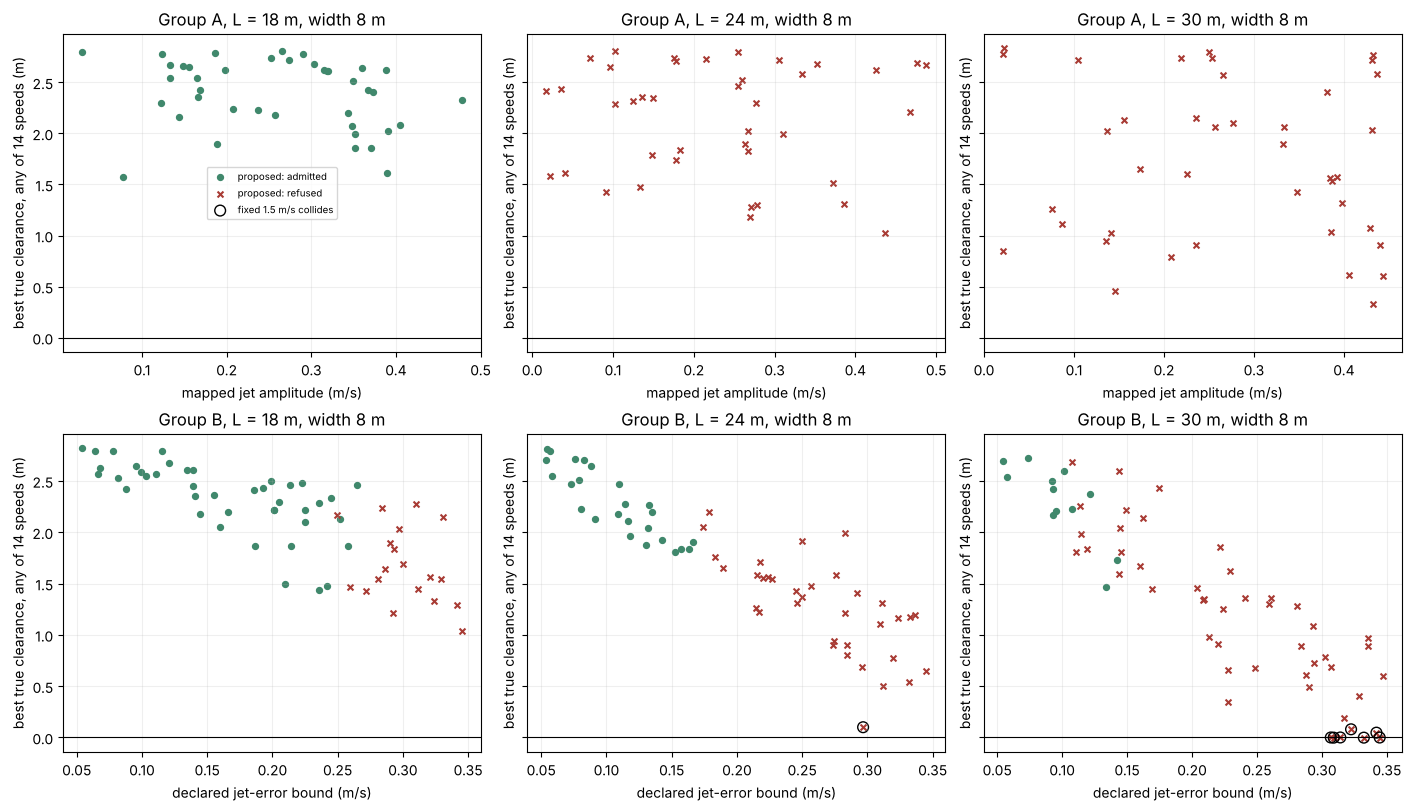

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout='constrained', sharey='row')
for row, (name, df) in enumerate((('A', A), ('B', B))):
    for ax, (L, g) in zip(axes[row], df.groupby('length')):
        adm = g.filter_admitted.fillna(False).astype(bool)
        x = g.declared_jet if name == 'B' else g.jet_amplitude
        ax.scatter(x[adm], g.oracle_best_clearance[adm], c='#40886c', s=18, label='proposed: admitted')
        ax.scatter(x[~adm], g.oracle_best_clearance[~adm], c='#a83b34', s=18, marker='x', label='proposed: refused')
        fail15 = g['oracle_clear_1.5'] <= 0
        ax.scatter(x[fail15], g.oracle_best_clearance[fail15], facecolors='none', edgecolors='k', s=60,
                   label='fixed 1.5 m/s collides')
        ax.axhline(0, color='k', lw=.8)
        ax.set(title=f'Group {name}, L = {L:.0f} m, width 8 m',
               xlabel='declared jet-error bound (m/s)' if name == 'B' else 'mapped jet amplitude (m/s)',
               ylabel='best true clearance, any of 14 speeds (m)')
        ax.grid(alpha=.2)
axes[0, 0].legend(fontsize=7)
fig.savefig(FIG/'same_geometry.png', dpi=200); fig.savefig(FIG/'same_geometry.pdf')
plt.show()

## 结论

数字取自上面的实际运行（统一参数；横荡速度误差界 GNSS 可用时 0.025 m/s、断星时 0.015 m/s；8 m 宽）。

**A 组：只改变已知海流和入口状态（结果不好）**
- 在 18/24/30 m 上，120 个世界全部能过；固定 1.5 m/s 的桥长门槛全部放行也 0 撞墙、通过 120 次。
- 本文方法 18 m 放行 40/40，24 m 和 30 m 全部拒绝（通过 40 次）；EKF 3σ 全部放行、0 撞墙。
- 入口裕度主要由**已知**射流幅值决定（Spearman −0.94～−0.98），而真实间隙几乎不受它影响（−0.08～−0.32），真正决定结果的是**未知**射流误差的大小（−0.81～−0.97）。入口裕度与真实最佳间隙的相关只有 0.05～0.24。
- 解读：在声明误差界固定时，误差盒在同一座桥上基本退化为桥长门槛，而且会因为海图射流强而多拒（误差盒里的射流梯度耦合项按已知射流幅值放大）。已知的入口偏差和背景流在本仿真里几乎不影响能否通过，所以 A 组没有“该拒”的世界可供区分。这一组不支持“误差盒比桥长门槛更会区分”。

**B 组：各桥位海流图精度不同（方法知道各自的声明射流误差界 B）**

| 桥长 | 18 m | 24 m | 30 m |
|---|---|---|---|
| 不可通过 / 世界数 | 0/60 | 0/60 | 5/60 |
| 桥长门槛（固定 1.5 m/s 全放）撞墙 | 0 | 1 | 7 |
| 本文方法 放行 / 撞墙 | 41 / 0 | 25 / 0 | 12 / 0 |
| EKF 3σ 放行 / 撞墙 | 60 / 0 | 52 / 0 | 39 / 0 |

- 同几何下，声明误差界改变了放行决策：本文方法在 24、30 m 仍放行海流图精度高的桥，拒绝了全部 5 个不可通过的世界，三个桥长合计 0 撞墙、通过 78 次，最小间隙 1.13 m。只看桥长的规则要做到 0 撞墙只能在 18 m 放行（通过 60 次）。
- 更简单的基线也很强：“固定 1.5 m/s + 声明射流误差界 ≤ 0.22 才进”通过 95 次、0 撞墙，最小间隙 0.98 m；门槛放宽到 0.25 仍 0 撞墙、通过 117 次，最小间隙 0.35 m（门槛为事后选取）。
- 30 m 上只有 5 个不可通过样本；单用声明误差界排序的 AUC 为 0.90，本文方法入口裕度为 0.92。入口裕度与真实最佳间隙的 Spearman 相关 0.80～0.91，放行与否主要由声明界 B 决定（−0.97～−0.98）。
- EKF 3σ 在 B 组同样 0 撞墙且放行更多（151 次），因为这里的真实误差都在声明界内、并且最多用到 1.0 倍。它的弱点在误差取到界上或超界时（04、05）。

**结论**：同几何下，桥位的声明误差界会改变放行决策，误差界本身有决策价值。本文方法相对简单的误差界门槛，增益不在通过次数（78 对 95），而在不需要事后标定门槛、并留出更大的间隙；通行次数与间隙之间存在取舍。声明误差界相同时，误差盒不比桥长门槛更会区分（A 组）。